# Task 3 · Car Price Prediction with Machine Learning

Predict the selling price of a used vehicle from its brand, age, kilometres, fuel type, and transmission.

The file is the public CarDekho vehicle table (`Car_Name`, `Year`, `Selling_Price`, `Present_Price`, `Kms_Driven`, `Fuel_Type`, `Seller_Type`, `Transmission`, `Owner`). Prices are in **lakh rupees**. The name column is the model, and the file mixes cars with two-wheelers, so brand has to be read off the model name rather than taken as the first word.


## 1. Setup


In [1]:
%matplotlib inline
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
pd.set_option("display.max_rows", 40)

DATA_PATH = Path("data") / "car_data.csv"


## 2. Load


In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
print()
print(raw.dtypes)
raw.head()


Shape: (301, 9)

Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Cleaning

Three checks: missing values, exact duplicate rows, and categorical text that only differs by case or spacing (`Petrol` versus `petrol`). `CNG` is kept in capitals, because a plain title-case conversion would turn it into `Cng`.


In [3]:
print("Missing values:")
print(raw.isnull().sum())
print()
print("Duplicate rows:", int(raw.duplicated().sum()))
print()
for column in ["Fuel_Type", "Seller_Type", "Transmission"]:
    print(column, sorted(raw[column].astype(str).unique()))


Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate rows: 2

Fuel_Type ['CNG', 'Diesel', 'Petrol']
Seller_Type ['Dealer', 'Individual']
Transmission ['Automatic', 'Manual']


In [4]:
df = raw.copy()
df = df.drop_duplicates().reset_index(drop=True)

for column in ["Car_Name", "Fuel_Type", "Seller_Type", "Transmission"]:
    df[column] = df[column].astype(str).str.strip()

df["Fuel_Type"] = df["Fuel_Type"].str.lower().replace({
    "petrol": "Petrol",
    "diesel": "Diesel",
    "cng": "CNG",
})
df["Seller_Type"] = df["Seller_Type"].str.title()
df["Transmission"] = df["Transmission"].str.title()

print("Rows after dropping duplicates:", len(df))
print("Fuel:", sorted(df["Fuel_Type"].unique()))
print("Seller:", sorted(df["Seller_Type"].unique()))
print("Transmission:", sorted(df["Transmission"].unique()))
print("Missing values left:", int(df.isnull().sum().sum()))


Rows after dropping duplicates: 299
Fuel: ['CNG', 'Diesel', 'Petrol']
Seller: ['Dealer', 'Individual']
Transmission: ['Automatic', 'Manual']
Missing values left: 0


The file has **301 rows and no missing values**. Two rows are exact copies, so they are dropped and **299 listings** remain. Fuel, seller, and transmission were already spelled consistently (`Petrol`, `Diesel`, `CNG`, `Dealer`, `Individual`, `Manual`, `Automatic`). The cleaning step still lowercases and remaps them, so a later file with `petrol` or `PETROL` would land in the same category.


## 4. Feature engineering

**Age.** The newest model year in the file is 2018, which is when these listings were collected. Age is `2018 − Year`. A 2018 vehicle has age 0. Measuring age from the current calendar year would add the same number of years to every row and would not match the prices in the file.

**Brand.** `Car_Name` is a model (`swift`, `fortuner`, `Royal Enfield Classic 350`), not a manufacturer. The function below maps each model onto its brand. Brands with fewer than five listings are grouped as `Other`, so a single UM or Hyosung row does not become its own column.


In [5]:
# Model name -> manufacturer. The first matching rule wins.
BRAND_RULES = [
    ("royal enfield", "Royal Enfield"),
    ("hero", "Hero"),
    ("bajaj", "Bajaj"),
    ("tvs", "TVS"),
    ("yamaha", "Yamaha"),
    ("ktm", "KTM"),
    ("hyosung", "Hyosung"),
    ("mahindra", "Mahindra"),
    ("um renegade", "UM"),
    ("suzuki", "Suzuki"),
    ("activa", "Honda"),
    ("honda", "Honda"),
    ("city", "Honda"),
    ("brio", "Honda"),
    ("amaze", "Honda"),
    ("jazz", "Honda"),
    ("grand i10", "Hyundai"),
    ("i10", "Hyundai"),
    ("i20", "Hyundai"),
    ("eon", "Hyundai"),
    ("xcent", "Hyundai"),
    ("creta", "Hyundai"),
    ("verna", "Hyundai"),
    ("elantra", "Hyundai"),
    ("innova", "Toyota"),
    ("fortuner", "Toyota"),
    ("corolla", "Toyota"),
    ("etios", "Toyota"),
    ("camry", "Toyota"),
    ("land cruiser", "Toyota"),
    ("wagon r", "Maruti"),
    ("vitara", "Maruti"),
    ("alto", "Maruti"),
    ("s cross", "Maruti"),
    ("ritz", "Maruti"),
    ("sx4", "Maruti"),
    ("ciaz", "Maruti"),
    ("swift", "Maruti"),
    ("dzire", "Maruti"),
    ("ertiga", "Maruti"),
    ("baleno", "Maruti"),
    ("ignis", "Maruti"),
    ("omni", "Maruti"),
    ("800", "Maruti"),
]


def brand_from_name(name):
    cleaned = " ".join(str(name).lower().split())
    for prefix, brand in BRAND_RULES:
        if cleaned == prefix or cleaned.startswith(prefix + " "):
            return brand
    return "Other"


df["brand"] = df["Car_Name"].map(brand_from_name)
rare_brands = df["brand"].value_counts()
rare_brands = rare_brands[rare_brands < 5].index
df["brand"] = df["brand"].where(~df["brand"].isin(rare_brands), "Other")

# Age is measured from the newest model year in this file, not from today.
reference_year = int(df["Year"].max())
df["car_age"] = reference_year - df["Year"]

print("Reference year:", reference_year)
print("Unmapped names:", sorted(df.loc[df["brand"].eq("Other"), "Car_Name"].unique()))
print()
print(df["brand"].value_counts())
df[["Car_Name", "brand", "Year", "car_age", "Selling_Price"]].head(8)


Reference year: 2018
Unmapped names: ['Hyosung GT250R', 'KTM 390 Duke', 'KTM RC200', 'KTM RC390', 'Mahindra Mojo XT300', 'Suzuki Access 125', 'UM Renegade Mojave']

brand
Honda            70
Hyundai          50
Maruti           49
Toyota           49
Bajaj            25
Royal Enfield    17
Hero             15
Other             8
Yamaha            8
TVS               8
Name: count, dtype: int64


,Car_Name,brand,Year,car_age,Selling_Price
0,ritz,Maruti,2014,4,3.35
1,sx4,Maruti,2013,5,4.75
2,ciaz,Maruti,2017,1,7.25
3,wagon r,Maruti,2011,7,2.85
4,swift,Maruti,2014,4,4.60
5,vitara brezza,Maruti,2018,0,9.25
6,ciaz,Maruti,2015,3,6.75
7,s cross,Maruti,2015,3,6.50


## 5. Selling price distribution

`Present_Price` is the showroom price of the same vehicle. It tracks the selling price very closely, so it is kept for this picture of the data and left out of the model. The model is meant to price a listing from brand, age, kilometres, fuel, seller, transmission, and previous owners.


In [6]:
df[["Selling_Price", "Present_Price", "Kms_Driven", "car_age", "Owner"]].describe()


,Selling_Price,Present_Price,Kms_Driven,car_age,Owner
count,299.000,299.000,299.000,299.000,299.000
mean,4.590,7.541,36916.753,4.385,0.043
std,4.984,8.568,39015.170,2.897,0.249
min,0.100,0.320,500.000,0.000,0.000
25%,0.850,1.200,15000.000,2.000,0.000
50%,3.510,6.100,32000.000,4.000,0.000
75%,6.000,9.840,48883.500,6.000,0.000
max,35.000,92.600,500000.000,15.000,3.000


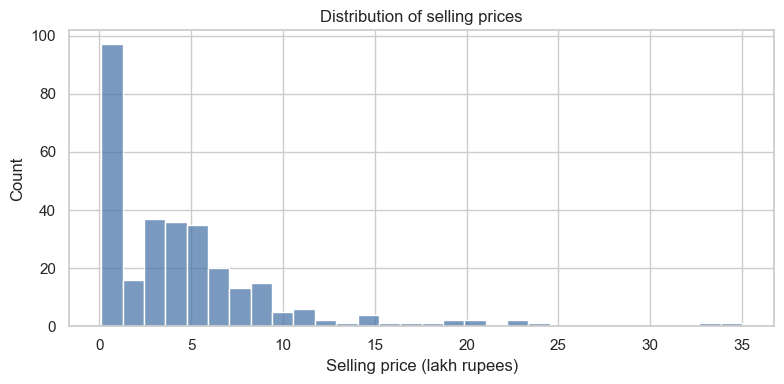

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["Selling_Price"], bins=30, ax=ax, color="#4C78A8")
ax.set_xlabel("Selling price (lakh rupees)")
ax.set_title("Distribution of selling prices")
fig.tight_layout()
plt.show()


Selling prices are pulled to the right. Most listings are only a few lakh, the median is about **3.6 lakh**, and a thin tail reaches **35 lakh**. A model that only learns the average will miss both the cheap two-wheelers and the expensive tail.


## 6. Price by fuel type


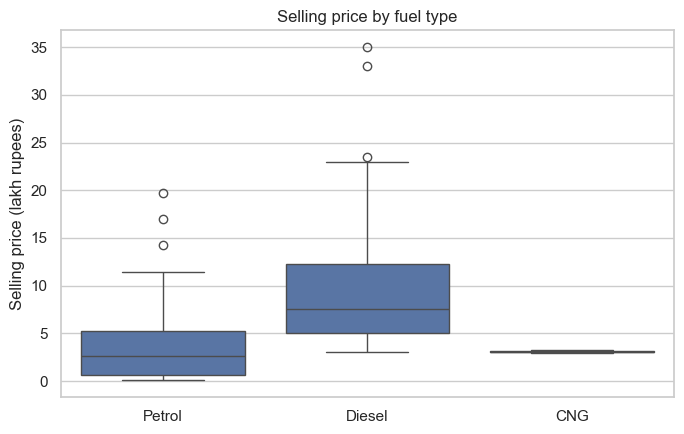

Fuel_Type
CNG       3.10
Diesel    7.60
Petrol    2.65
Name: median_selling_price, dtype: float64

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(
    data=df,
    x="Fuel_Type",
    y="Selling_Price",
    order=["Petrol", "Diesel", "CNG"],
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("Selling price (lakh rupees)")
ax.set_title("Selling price by fuel type")
fig.tight_layout()
plt.show()

df.groupby("Fuel_Type")["Selling_Price"].median().rename("median_selling_price")


Diesel listings have a higher median, about **7.6 lakh**, against about **2.7 lakh** for petrol. That gap is not only a fuel effect. The file's two-wheelers are petrol and cheap, so they pull the petrol box down. CNG is only two cars (`wagon r` and `sx4`), so that box is not a fuel-type pattern.


## 7. Price against car age


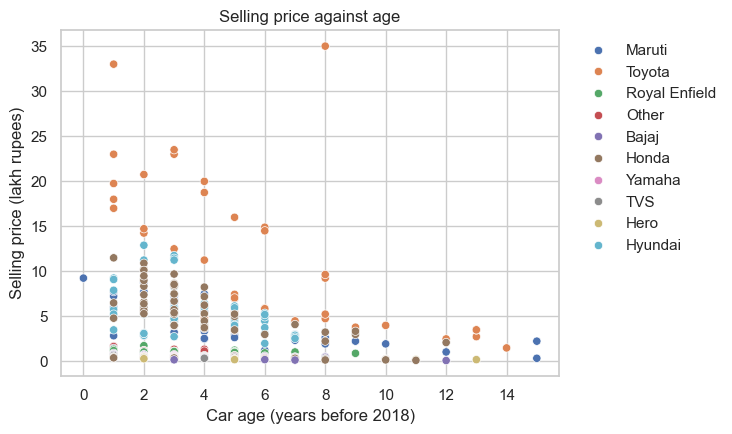

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.scatterplot(data=df, x="car_age", y="Selling_Price", hue="brand", ax=ax)
ax.set_xlabel("Car age (years before 2018)")
ax.set_ylabel("Selling price (lakh rupees)")
ax.set_title("Selling price against age")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.tight_layout()
plt.show()


Older vehicles tend to sell for less, but the cloud is wide at every age. A new two-wheeler and a new Toyota sit at the same age and very different prices. Age is a real signal, and it does not set the price on its own. Brand is doing a lot of the separating in this plot.


## 8. Encode categories and look at correlation

Fuel, seller, transmission, and brand are one-hot encoded. `drop_first=True` leaves one level out of each category so the linear model does not get a redundant column. The heatmap includes the selling price, so the row for price shows which encoded columns move with it.


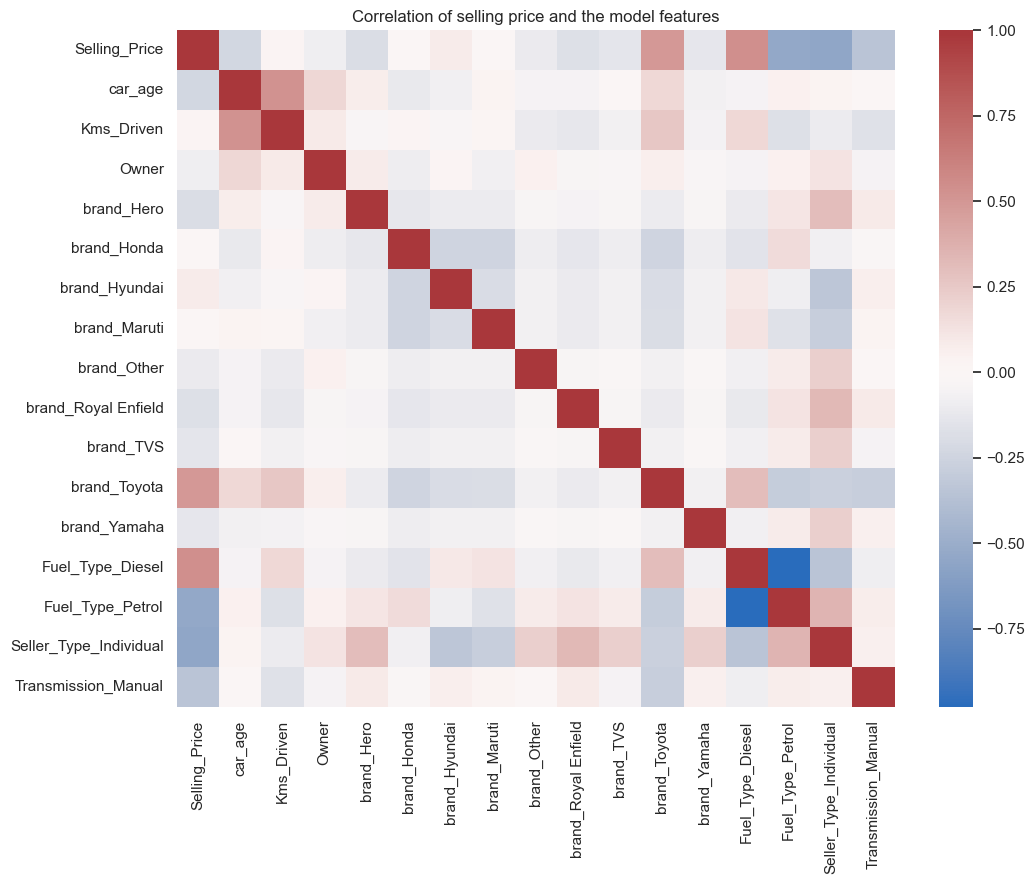

In [10]:
model_columns = [
    "car_age",
    "Kms_Driven",
    "Owner",
    "brand",
    "Fuel_Type",
    "Seller_Type",
    "Transmission",
]
encoded = pd.get_dummies(df[model_columns], drop_first=True)
encoded.insert(0, "Selling_Price", df["Selling_Price"])

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(encoded.corr(), cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation of selling price and the model features")
fig.tight_layout()
plt.show()


The strongest lines with selling price are the Toyota column, diesel, and an individual seller (individual listings are the cheaper two-wheelers more often than the cars). Kilometres barely show up as a straight-line correlation, because a high-kilometre car and a low-kilometre bike are not the same kind of vehicle. Age is a mild negative line. The heatmap is why the model needs brand and fuel together with age and kilometres, not any one of them alone.


## 9. Train/test split and models

The split is 80/20 (`random_state=42`): 239 listings to fit, 60 to test.

Linear regression is the straight-line baseline. A random forest (300 trees) and a gradient boosting model can follow combinations such as "old and high-kilometre" or "Toyota and diesel" without assuming a fixed step per year.


In [11]:
X = encoded.drop(columns=["Selling_Price"])
y = encoded["Selling_Price"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
predictions = {}
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    predictions[name] = model.predict(X_test)


Training rows: 239
Test rows: 60


## 10. Evaluation

Prices are in lakh rupees, so MAE and RMSE are too. R² is the share of test-set price variation the predictions capture.


In [12]:
score_rows = []
for name, predicted in predictions.items():
    score_rows.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, predicted),
        "RMSE": root_mean_squared_error(y_test, predicted),
        "R2": r2_score(y_test, predicted),
    })
scores = pd.DataFrame(score_rows).set_index("model")
scores = scores.sort_values(["R2", "MAE"], ascending=[False, True])
scores


,MAE,RMSE,R2
model,,,
Gradient Boosting,1.458,2.564,0.745
Random Forest,1.551,3.152,0.614
Linear Regression,1.949,3.306,0.576


## 11. Feature importance for the best model

Gradient boosting is ahead on every test metric, so the importance chart is taken from that model. Each bar is the share of the model's splits that used the feature.


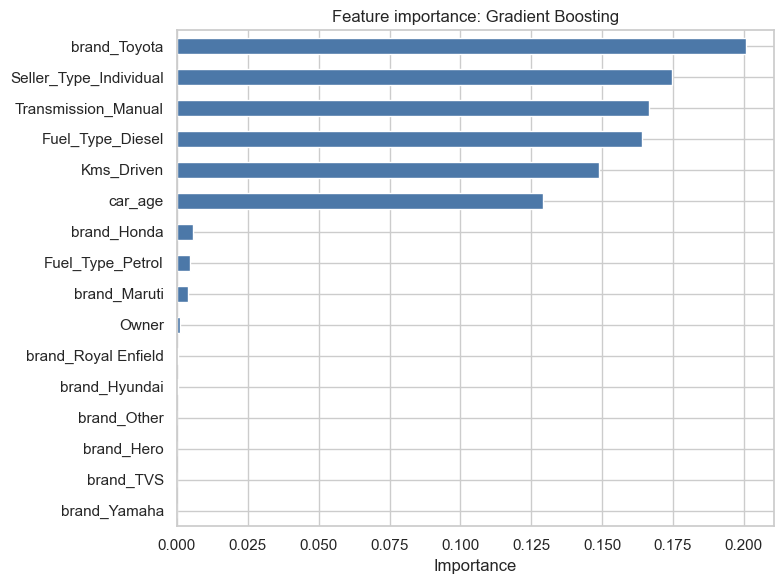

In [13]:
best_name = scores.index[0]
importances = pd.Series(
    fitted[best_name].feature_importances_,
    index=X.columns,
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
importances.plot.barh(ax=ax, color="#4C78A8")
ax.set_xlabel("Importance")
ax.set_ylabel("")
ax.set_title(f"Feature importance: {best_name}")
fig.tight_layout()
plt.show()


## 12. Best model

**Gradient boosting is the best of the three on the 60 held-out listings.**

| Model | MAE (lakh) | RMSE (lakh) | R² |
| --- | ---: | ---: | ---: |
| Gradient boosting | 1.458 | 2.564 | 0.745 |
| Random forest | 1.551 | 3.152 | 0.614 |
| Linear regression | 1.949 | 3.306 | 0.576 |

Boosting explains about three quarters of the test-set price variation. Its typical miss is about **1.5 lakh**, against about **1.9 lakh** for the straight line. The forest is in between on MAE and clearly behind on RMSE, so its larger misses cost it.

The importance chart matches the plots. Toyota is the strongest single column, then individual seller, manual transmission, diesel, kilometres, and age. Those six account for almost all of the model's splits. The remaining brand columns are small because Toyota, diesel, and the seller type already separate the expensive cars from the cheap two-wheelers.

Two limits are worth keeping. An error of 1.5 lakh is large next to a median price of 3.6 lakh, so the model is better at ranking listings than at quoting a tight price. And Honda in this file is both cars (City, Amaze) and scooters (Activa), so that one brand label is a blend.
